# Práctica 7. Búsqueda aplicada: restricciones (CSP) y algoritmo genético

**Materia:** Inteligencia Artificial
**Unidad:** 2. Resolución de problemas por métodos de búsqueda

## Objetivo

Resolver un problema de satisfacción de restricciones mediante backtracking y heurísticas, así como un problema de optimización del agente viajero mediante un algoritmo genético.

## Parte A. Coloreo de mapas mediante CSP

Se formulará el coloreo del mapa de la región centro de México como un problema de satisfacción de restricciones (CSP), identificando sus variables, dominios y restricciones.

Se implementará backtracking con las heurísticas MRV, grado y LCV, además de forward checking. Se comprobará el comportamiento del algoritmo utilizando tres y cuatro colores.

## Definir las variables, dominios y restricciones

In [1]:
# ---------------------------------------------------------
# PRÁCTICA 7 - PARTE A
# COLOREO DE MAPAS MEDIANTE CSP
# ---------------------------------------------------------

# 1. VARIABLES
# Cada entidad federativa representa una variable del CSP.

regiones = [
    "CDMX",
    "Edomex",
    "Morelos",
    "Puebla",
    "Tlaxcala",
    "Hidalgo",
    "Querétaro",
    "Guerrero",
    "Michoacán"
]

# 2. DOMINIOS
# Los colores disponibles se definirán en cada experimento.
# Primero probaremos con 3 colores y después con 4.

colores_3 = ["Rojo", "Verde", "Azul"]

colores_4 = ["Rojo", "Verde", "Azul", "Amarillo"]

# 3. RESTRICCIONES
# Dos regiones que comparten frontera terrestre deben
# recibir colores diferentes.

# Definimos las relaciones de vecindad del mapa.
# Cada par representa una frontera entre dos regiones.

fronteras = [
    ("CDMX", "Edomex"),
    ("CDMX", "Morelos"),

    ("Edomex", "Morelos"),
    ("Edomex", "Puebla"),
    ("Edomex", "Tlaxcala"),
    ("Edomex", "Hidalgo"),
    ("Edomex", "Querétaro"),
    ("Edomex", "Guerrero"),
    ("Edomex", "Michoacán"),

    ("Morelos", "Puebla"),
    ("Morelos", "Guerrero"),

    ("Puebla", "Tlaxcala"),
    ("Puebla", "Hidalgo"),
    ("Puebla", "Guerrero"),

    ("Tlaxcala", "Hidalgo"),

    ("Hidalgo", "Querétaro"),

    ("Querétaro", "Michoacán"),

    ("Guerrero", "Michoacán")
]

# ---------------------------------------------------------
# CONSTRUIR EL DICCIONARIO DE VECINOS
# ---------------------------------------------------------

# Creamos un conjunto vacío de vecinos para cada región.
vecinos = {region: set() for region in regiones}

# Como las fronteras son bidireccionales,
# agregamos cada relación en ambos sentidos.
for region_a, region_b in fronteras:

    vecinos[region_a].add(region_b)
    vecinos[region_b].add(region_a)

# ---------------------------------------------------------
# MOSTRAR LA FORMULACIÓN DEL CSP
# ---------------------------------------------------------

print("VARIABLES DEL CSP:")
print(regiones)

print("\nDOMINIO DE 3 COLORES:")
print(colores_3)

print("\nDOMINIO DE 4 COLORES:")
print(colores_4)

print("\nRESTRICCIONES DE VECINDAD:")

for region in regiones:
    print(f"{region}: {', '.join(sorted(vecinos[region]))}")

print("\nTOTAL DE VARIABLES:", len(regiones))
print("TOTAL DE FRONTERAS:", len(fronteras))

VARIABLES DEL CSP:
['CDMX', 'Edomex', 'Morelos', 'Puebla', 'Tlaxcala', 'Hidalgo', 'Querétaro', 'Guerrero', 'Michoacán']

DOMINIO DE 3 COLORES:
['Rojo', 'Verde', 'Azul']

DOMINIO DE 4 COLORES:
['Rojo', 'Verde', 'Azul', 'Amarillo']

RESTRICCIONES DE VECINDAD:
CDMX: Edomex, Morelos
Edomex: CDMX, Guerrero, Hidalgo, Michoacán, Morelos, Puebla, Querétaro, Tlaxcala
Morelos: CDMX, Edomex, Guerrero, Puebla
Puebla: Edomex, Guerrero, Hidalgo, Morelos, Tlaxcala
Tlaxcala: Edomex, Hidalgo, Puebla
Hidalgo: Edomex, Puebla, Querétaro, Tlaxcala
Querétaro: Edomex, Hidalgo, Michoacán
Guerrero: Edomex, Michoacán, Morelos, Puebla
Michoacán: Edomex, Guerrero, Querétaro

TOTAL DE VARIABLES: 9
TOTAL DE FRONTERAS: 18


## Implementar backtracking con MRV, grado, LCV y forward checking

In [2]:
# ---------------------------------------------------------
# PRÁCTICA 7 - PARTE A
# BACKTRACKING CON HEURÍSTICAS Y FORWARD CHECKING
# ---------------------------------------------------------

def resolver_csp(regiones, vecinos, colores):

    # Cada región comienza con todos los colores disponibles.
    dominios = {
        region: colores.copy()
        for region in regiones
    }

    # Guardará los colores asignados a cada región.
    asignacion = {}

    # Estadísticas para analizar el algoritmo.
    estadisticas = {
        "nodos_explorados": 0,
        "retrocesos": 0
    }

    # -----------------------------------------------------
    # MRV + HEURÍSTICA DE GRADO
    # -----------------------------------------------------

    def seleccionar_variable(dominios_actuales):

        pendientes = [
            region for region in regiones
            if region not in asignacion
        ]

        # MRV: elegir la región con menos colores disponibles.
        # Grado: en caso de empate, elegir la región que
        # tenga más vecinos todavía sin colorear.

        return min(
            pendientes,
            key=lambda region: (
                len(dominios_actuales[region]),
                -sum(
                    1 for vecino in vecinos[region]
                    if vecino not in asignacion
                ),
                region
            )
        )

    # -----------------------------------------------------
    # LCV: VALOR MENOS RESTRICTIVO
    # -----------------------------------------------------

    def ordenar_colores(region, dominios_actuales):

        def restricciones_generadas(color):

            # Contamos cuántas opciones perderían los
            # vecinos no asignados si usamos este color.
            return sum(
                1
                for vecino in vecinos[region]
                if vecino not in asignacion
                and color in dominios_actuales[vecino]
            )

        return sorted(
            dominios_actuales[region],
            key=lambda color: (
                restricciones_generadas(color),
                colores.index(color)
            )
        )

    # -----------------------------------------------------
    # FORWARD CHECKING
    # -----------------------------------------------------

    def aplicar_forward_checking(
        region, color, dominios_actuales
    ):

        # Copiamos los dominios para no alterar los
        # utilizados en otros caminos de búsqueda.
        nuevos_dominios = {
            variable: valores.copy()
            for variable, valores in dominios_actuales.items()
        }

        nuevos_dominios[region] = [color]

        for vecino in vecinos[region]:

            if vecino in asignacion:
                # Una región ya coloreada no puede
                # compartir color con la región actual.
                if asignacion[vecino] == color:
                    return None

            else:
                # Eliminamos el color elegido del dominio
                # de cada vecino que aún no está coloreado.
                if color in nuevos_dominios[vecino]:
                    nuevos_dominios[vecino].remove(color)

                # Si un vecino se queda sin colores,
                # esta asignación no puede funcionar.
                if not nuevos_dominios[vecino]:
                    return None

        return nuevos_dominios

    # -----------------------------------------------------
    # BACKTRACKING RECURSIVO
    # -----------------------------------------------------

    def backtracking(dominios_actuales):

        # Si todas las regiones tienen color,
        # encontramos una solución completa.
        if len(asignacion) == len(regiones):
            return asignacion.copy()

        # Seleccionamos la siguiente región mediante
        # MRV y la heurística de grado.
        region = seleccionar_variable(dominios_actuales)

        # Probamos los colores según LCV.
        for color in ordenar_colores(region, dominios_actuales):

            estadisticas["nodos_explorados"] += 1

            # Comprobamos las restricciones con
            # las regiones previamente coloreadas.
            if any(
                asignacion.get(vecino) == color
                for vecino in vecinos[region]
            ):
                continue

            asignacion[region] = color

            # Reducimos los dominios de los vecinos.
            nuevos_dominios = aplicar_forward_checking(
                region, color, dominios_actuales
            )

            if nuevos_dominios is not None:

                resultado = backtracking(nuevos_dominios)

                if resultado is not None:
                    return resultado

            # Si no funciona, deshacemos la asignación.
            del asignacion[region]
            estadisticas["retrocesos"] += 1

        return None

    solucion = backtracking(dominios)

    return solucion, estadisticas


# ---------------------------------------------------------
# VERIFICAR QUE UNA SOLUCIÓN SEA VÁLIDA
# ---------------------------------------------------------

def verificar_coloreo(solucion, regiones, fronteras, colores):

    if solucion is None:
        return False

    # Deben estar coloreadas exactamente las 9 regiones.
    if set(solucion) != set(regiones):
        return False

    # Todos los colores utilizados deben pertenecer
    # al dominio del experimento.
    if any(
        color not in colores
        for color in solucion.values()
    ):
        return False

    # Ninguna pareja de regiones vecinas puede
    # tener el mismo color.
    for region_a, region_b in fronteras:

        if solucion[region_a] == solucion[region_b]:
            return False

    return True


print("Funciones del CSP definidas correctamente.")

Funciones del CSP definidas correctamente.


## Ejecutar las pruebas con 3 y 4 colores

In [3]:
# ---------------------------------------------------------
# PRÁCTICA 7 - PARTE A
# EXPERIMENTOS CON 3 Y 4 COLORES
# ---------------------------------------------------------

resultados_csp = {}

for cantidad, colores in [
    (3, colores_3),
    (4, colores_4)
]:

    solucion, estadisticas = resolver_csp(
        regiones,
        vecinos,
        colores
    )

    es_valida = verificar_coloreo(
        solucion,
        regiones,
        fronteras,
        colores
    )

    resultados_csp[cantidad] = {
        "solucion": solucion,
        "estadisticas": estadisticas,
        "valida": es_valida
    }

    print("=" * 55)
    print(f"EXPERIMENTO CON {cantidad} COLORES")
    print("=" * 55)

    if solucion is None:
        print("No se encontró una solución.")

    else:
        print("Solución encontrada:")

        for region in regiones:
            print(f"  {region}: {solucion[region]}")

    print("\nVALIDACIÓN:")
    print("Coloreo válido:", es_valida)

    print("\nESTADÍSTICAS:")
    print(
        "Nodos explorados:",
        estadisticas["nodos_explorados"]
    )
    print(
        "Retrocesos:",
        estadisticas["retrocesos"]
    )

    print()

EXPERIMENTO CON 3 COLORES
No se encontró una solución.

VALIDACIÓN:
Coloreo válido: False

ESTADÍSTICAS:
Nodos explorados: 15
Retrocesos: 15

EXPERIMENTO CON 4 COLORES
Solución encontrada:
  CDMX: Verde
  Edomex: Rojo
  Morelos: Amarillo
  Puebla: Verde
  Tlaxcala: Amarillo
  Hidalgo: Azul
  Querétaro: Amarillo
  Guerrero: Azul
  Michoacán: Verde

VALIDACIÓN:
Coloreo válido: True

ESTADÍSTICAS:
Nodos explorados: 9
Retrocesos: 0



## Visualizar el grafo coloreado

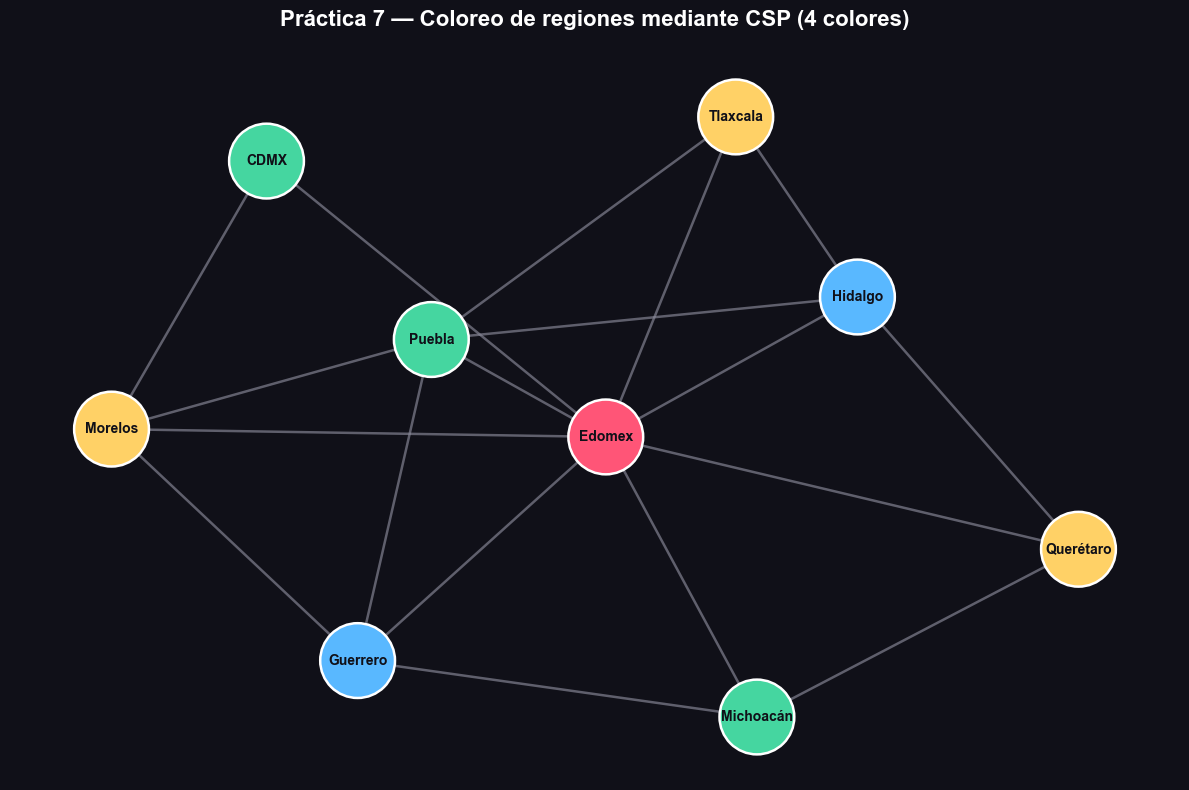

In [4]:
# ---------------------------------------------------------
# PRÁCTICA 7 - PARTE A
# VISUALIZACIÓN DEL COLOREO DEL GRAFO
# ---------------------------------------------------------

import networkx as nx
import matplotlib.pyplot as plt

# Recuperar la solución de cuatro colores.
solucion_4 = resultados_csp[4]["solucion"]

# Construir el grafo de vecindades.
grafo = nx.Graph()
grafo.add_nodes_from(regiones)
grafo.add_edges_from(fronteras)

# Asociar cada nombre de color con un color de Matplotlib.
paleta = {
    "Rojo": "#FF5577",
    "Verde": "#45D6A0",
    "Azul": "#59B8FF",
    "Amarillo": "#FFD166"
}

colores_nodos = [
    paleta[solucion_4[region]]
    for region in grafo.nodes()
]

# Distribución reproducible de los nodos.
posiciones = nx.spring_layout(
    grafo,
    seed=42,
    k=1.2
)

fig, ax = plt.subplots(figsize=(12, 8))

fig.patch.set_facecolor("#101018")
ax.set_facecolor("#101018")

nx.draw_networkx_edges(
    grafo,
    posiciones,
    ax=ax,
    edge_color="#8A8A9A",
    width=1.8,
    alpha=0.65
)

nx.draw_networkx_nodes(
    grafo,
    posiciones,
    ax=ax,
    node_color=colores_nodos,
    node_size=2900,
    edgecolors="white",
    linewidths=1.8
)

nx.draw_networkx_labels(
    grafo,
    posiciones,
    ax=ax,
    font_size=10,
    font_weight="bold",
    font_color="#101018"
)

ax.set_title(
    "Práctica 7 — Coloreo de regiones mediante CSP (4 colores)",
    fontsize=16,
    fontweight="bold",
    color="white",
    pad=20
)

ax.axis("off")
plt.tight_layout()
plt.show()

## Parte B. Problema del agente viajero mediante algoritmo genético

El problema consiste en encontrar una ruta de distancia mínima que visite las 15 ciudades exactamente una vez y regrese a la ciudad inicial.

Se implementará un algoritmo genético con selección por torneo, cruza de orden (OX), mutación por inversión y elitismo. Sus resultados se compararán con una búsqueda aleatoria utilizando el mismo número de evaluaciones.

CIUDADES GENERADAS (SEMILLA 42)

Ciudad 00: X = 77.40, Y = 43.89
Ciudad 01: X = 85.86, Y = 69.74
Ciudad 02: X = 9.42, Y = 97.56
Ciudad 03: X = 76.11, Y = 78.61
Ciudad 04: X = 12.81, Y = 45.04
Ciudad 05: X = 37.08, Y = 92.68
Ciudad 06: X = 64.39, Y = 82.28
Ciudad 07: X = 44.34, Y = 22.72
Ciudad 08: X = 55.46, Y = 6.38
Ciudad 09: X = 82.76, Y = 63.17
Ciudad 10: X = 75.81, Y = 35.45
Ciudad 11: X = 97.07, Y = 89.31
Ciudad 12: X = 77.84, Y = 19.46
Ciudad 13: X = 46.67, Y = 4.38
Ciudad 14: X = 15.43, Y = 68.30


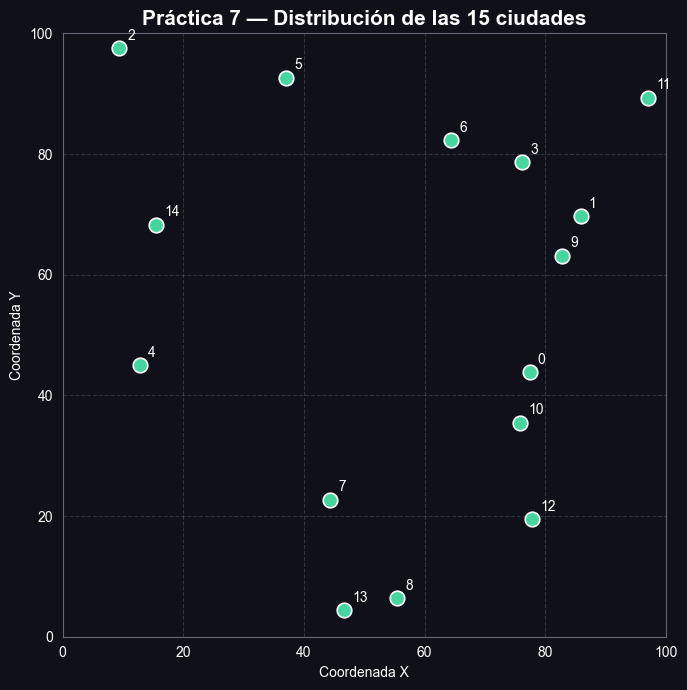

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Semilla para reproducir los resultados.
rng_ciudades = np.random.default_rng(42)

# Generar 15 ciudades en un plano de 100 x 100.
ciudades = rng_ciudades.uniform(0, 100, size=(15, 2))

# Mostrar las coordenadas.
print("CIUDADES GENERADAS (SEMILLA 42)\n")

for i, (x, y) in enumerate(ciudades):
    print(f"Ciudad {i:02d}: X = {x:.2f}, Y = {y:.2f}")

# Visualizar las ciudades.
fig, ax = plt.subplots(figsize=(9, 7))

fig.patch.set_facecolor("#101018")
ax.set_facecolor("#101018")

ax.scatter(
    ciudades[:, 0],
    ciudades[:, 1],
    color="#45D6A0",
    s=110,
    edgecolors="white",
    linewidths=1.2
)

for i, (x, y) in enumerate(ciudades):
    ax.annotate(
        str(i),
        (x, y),
        xytext=(6, 6),
        textcoords="offset points",
        color="white",
        fontsize=10
    )

ax.set_title(
    "Práctica 7 — Distribución de las 15 ciudades",
    color="white",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Coordenada X", color="white")
ax.set_ylabel("Coordenada Y", color="white")

ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.set_aspect("equal")

ax.tick_params(colors="white")
ax.grid(alpha=0.15, linestyle="--")

for spine in ax.spines.values():
    spine.set_color("#666677")

plt.tight_layout()
plt.show()

## Implementar los operadores del algoritmo genético

In [6]:
# ---------------------------------------------------------
# PRÁCTICA 7 - PARTE B
# OPERADORES DEL ALGORITMO GENÉTICO
# ---------------------------------------------------------

import numpy as np

NUM_CIUDADES = len(ciudades)

# Matriz de distancias euclidianas entre ciudades.
matriz_distancias = np.linalg.norm(
    ciudades[:, None, :] - ciudades[None, :, :],
    axis=2
)


# ---------------------------------------------------------
# 1. VALIDACIÓN DE RUTAS
# ---------------------------------------------------------

def ruta_valida(ruta):
    """
    Comprueba que una ruta contenga todas las ciudades
    exactamente una vez, sin repeticiones ni omisiones.
    """
    return (
        len(ruta) == NUM_CIUDADES
        and set(ruta) == set(range(NUM_CIUDADES))
    )


# ---------------------------------------------------------
# 2. FUNCIÓN DE COSTO
# ---------------------------------------------------------

def distancia_ruta(ruta):
    """
    Calcula la distancia total de una ruta cerrada.
    Incluye el regreso desde la última ciudad a la primera.
    """
    if not ruta_valida(ruta):
        raise ValueError("La ruta contiene ciudades repetidas u omitidas.")

    return sum(
        matriz_distancias[
            ruta[i],
            ruta[(i + 1) % NUM_CIUDADES]
        ]
        for i in range(NUM_CIUDADES)
    )


# ---------------------------------------------------------
# 3. POBLACIÓN INICIAL
# ---------------------------------------------------------

def crear_poblacion(tamano, rng):
    """
    Genera rutas aleatorias válidas.
    Cada individuo es una permutación de las 15 ciudades.
    """
    return [
        rng.permutation(NUM_CIUDADES).tolist()
        for _ in range(tamano)
    ]


# ---------------------------------------------------------
# 4. SELECCIÓN POR TORNEO
# ---------------------------------------------------------

def seleccion_torneo(poblacion, costos, rng, k=3):
    """
    Selecciona aleatoriamente k candidatos y devuelve
    el que tenga la menor distancia total.
    """
    participantes = rng.choice(
        len(poblacion),
        size=k,
        replace=False
    )

    ganador = min(
        participantes,
        key=lambda indice: costos[indice]
    )

    return poblacion[ganador].copy()


# ---------------------------------------------------------
# 5. CRUZA DE ORDEN (OX)
# ---------------------------------------------------------

def cruza_ox(padre_1, padre_2, rng):
    """
    Conserva un segmento del primer padre y completa
    las posiciones restantes siguiendo el orden
    relativo de las ciudades del segundo padre.
    """
    n = len(padre_1)

    inicio, fin = sorted(
        rng.choice(n, size=2, replace=False)
    )

    hijo = [None] * n

    # Copiar el segmento del primer padre.
    hijo[inicio:fin + 1] = padre_1[inicio:fin + 1]

    # Recorrer el segundo padre desde la posición posterior
    # al segmento, con recorrido circular.
    orden_segundo_padre = (
        padre_2[fin + 1:] + padre_2[:fin + 1]
    )

    restantes = [
        ciudad
        for ciudad in orden_segundo_padre
        if ciudad not in hijo
    ]

    posiciones_libres = [
        posicion % n
        for posicion in range(fin + 1, fin + 1 + n)
        if hijo[posicion % n] is None
    ]

    for posicion, ciudad in zip(posiciones_libres, restantes):
        hijo[posicion] = ciudad

    return hijo


# ---------------------------------------------------------
# 6. MUTACIÓN POR INVERSIÓN
# ---------------------------------------------------------

def mutacion_inversion(ruta, probabilidad, rng):
    """
    Con cierta probabilidad, selecciona dos posiciones
    e invierte el orden del segmento comprendido entre ellas.
    """
    nueva_ruta = ruta.copy()

    if rng.random() < probabilidad:

        inicio, fin = sorted(
            rng.choice(len(nueva_ruta), size=2, replace=False)
        )

        nueva_ruta[inicio:fin + 1] = list(
            reversed(nueva_ruta[inicio:fin + 1])
        )

    return nueva_ruta


# ---------------------------------------------------------
# 7. ELITISMO
# ---------------------------------------------------------

def obtener_elite(poblacion, costos, cantidad=1):
    """
    Conserva los mejores individuos para transferirlos
    directamente a la siguiente generación.
    """
    mejores_indices = np.argsort(costos)[:cantidad]

    return [
        poblacion[indice].copy()
        for indice in mejores_indices
    ]


print("Operadores genéticos definidos correctamente.")

Operadores genéticos definidos correctamente.


## Comprobar que los operadores funcionan

In [7]:
# ---------------------------------------------------------
# PRUEBAS DE LOS OPERADORES GENÉTICOS
# ---------------------------------------------------------

rng_prueba = np.random.default_rng(123)

poblacion_prueba = crear_poblacion(10, rng_prueba)

costos_prueba = [
    distancia_ruta(ruta)
    for ruta in poblacion_prueba
]

padre_1 = seleccion_torneo(
    poblacion_prueba, costos_prueba, rng_prueba
)

padre_2 = seleccion_torneo(
    poblacion_prueba, costos_prueba, rng_prueba
)

hijo = cruza_ox(padre_1, padre_2, rng_prueba)

# Probabilidad 1.0 para garantizar que se aplique
# la mutación durante esta prueba.
hijo_mutado = mutacion_inversion(
    hijo, 1.0, rng_prueba
)

elite = obtener_elite(
    poblacion_prueba, costos_prueba, cantidad=1
)

print("VALIDACIÓN DE OPERADORES GENÉTICOS\n")

print("Población inicial válida:",
      all(ruta_valida(r) for r in poblacion_prueba))

print("Padre 1 válido:", ruta_valida(padre_1))
print("Padre 2 válido:", ruta_valida(padre_2))
print("Hijo OX válido:", ruta_valida(hijo))
print("Hijo mutado válido:", ruta_valida(hijo_mutado))
print("Élite válida:", all(ruta_valida(r) for r in elite))

print("\nEJEMPLO DE RUTA:")
print(hijo_mutado)

print("\nDISTANCIA DE LA RUTA:")
print(f"{distancia_ruta(hijo_mutado):.2f} unidades")

VALIDACIÓN DE OPERADORES GENÉTICOS

Población inicial válida: True
Padre 1 válido: True
Padre 2 válido: True
Hijo OX válido: True
Hijo mutado válido: True
Élite válida: True

EJEMPLO DE RUTA:
[7, 2, 0, 8, 9, 6, 10, 12, 14, 1, 11, 4, 5, 3, 13]

DISTANCIA DE LA RUTA:
827.22 unidades


## Implementar el algoritmo genético completo

In [8]:
# ---------------------------------------------------------
# PRÁCTICA 7 - PARTE B
# ALGORITMO GENÉTICO COMPLETO
# ---------------------------------------------------------

def algoritmo_genetico(
    tamano_poblacion=100,
    probabilidad_mutacion=0.2,
    max_evaluaciones=30000,
    semilla=42
):
    """
    Algoritmo genético para el problema del agente viajero.

    Operadores:
    - Selección por torneo
    - Cruza de orden (OX)
    - Mutación por inversión
    - Elitismo

    Cada evaluación corresponde a una llamada
    a distancia_ruta().
    """

    if tamano_poblacion < 3:
        raise ValueError(
            "La población debe tener al menos 3 individuos."
        )

    if not 0 <= probabilidad_mutacion <= 1:
        raise ValueError(
            "La probabilidad de mutación debe estar entre 0 y 1."
        )

    if max_evaluaciones < tamano_poblacion:
        raise ValueError(
            "El presupuesto debe cubrir la población inicial."
        )

    rng = np.random.default_rng(semilla)

    # -----------------------------------------------------
    # 1. POBLACIÓN INICIAL
    # -----------------------------------------------------

    poblacion = crear_poblacion(tamano_poblacion, rng)

    costos = [
        distancia_ruta(ruta)
        for ruta in poblacion
    ]

    evaluaciones = len(poblacion)
    generaciones = 0

    indice_mejor = int(np.argmin(costos))

    mejor_ruta = poblacion[indice_mejor].copy()
    mejor_distancia = costos[indice_mejor]

    historial = [(evaluaciones, mejor_distancia)]

    # -----------------------------------------------------
    # 2. EVOLUCIÓN GENÉTICA
    # -----------------------------------------------------

    while evaluaciones < max_evaluaciones:

        # ELITISMO:
        # Conservamos la mejor ruta de la población actual
        # junto con su costo, sin volver a evaluarla.

        indice_elite = int(np.argmin(costos))

        elite = poblacion[indice_elite].copy()
        costo_elite = costos[indice_elite]

        nueva_poblacion = [elite]
        nuevos_costos = [costo_elite]

        # Generar hijos hasta completar la población
        # o alcanzar el presupuesto de evaluaciones.

        while (
            len(nueva_poblacion) < tamano_poblacion
            and evaluaciones < max_evaluaciones
        ):

            # SELECCIÓN POR TORNEO
            padre_1 = seleccion_torneo(
                poblacion, costos, rng
            )

            padre_2 = seleccion_torneo(
                poblacion, costos, rng
            )

            # CRUZA DE ORDEN (OX)
            hijo = cruza_ox(
                padre_1, padre_2, rng
            )

            # MUTACIÓN POR INVERSIÓN
            hijo = mutacion_inversion(
                hijo,
                probabilidad_mutacion,
                rng
            )

            # VALIDACIÓN
            if not ruta_valida(hijo):
                raise ValueError(
                    "El algoritmo generó una ruta inválida."
                )

            # EVALUACIÓN:
            # Calculamos la distancia una sola vez.
            costo_hijo = distancia_ruta(hijo)
            evaluaciones += 1

            nueva_poblacion.append(hijo)
            nuevos_costos.append(costo_hijo)

            # Actualizar la mejor solución global.
            if costo_hijo < mejor_distancia:
                mejor_distancia = costo_hijo
                mejor_ruta = hijo.copy()

        # Actualizar la población y sus costos.
        poblacion = nueva_poblacion
        costos = nuevos_costos

        generaciones += 1

        historial.append(
            (evaluaciones, mejor_distancia)
        )

    return {
        "mejor_ruta": mejor_ruta,
        "mejor_distancia": mejor_distancia,
        "evaluaciones": evaluaciones,
        "generaciones": generaciones,
        "historial": historial
    }


print("Algoritmo genético definido correctamente.")

Algoritmo genético definido correctamente.


## Ejecutar una prueba pequeña

In [9]:
# ---------------------------------------------------------
# PRUEBA INICIAL DEL ALGORITMO GENÉTICO
# ---------------------------------------------------------

resultado_prueba = algoritmo_genetico(
    tamano_poblacion=30,
    probabilidad_mutacion=0.2,
    max_evaluaciones=300,
    semilla=42
)

print("RESULTADOS DE LA PRUEBA\n")

print("Mejor ruta:")
print(resultado_prueba["mejor_ruta"])

print("\nMejor distancia:")
print(f'{resultado_prueba["mejor_distancia"]:.2f} unidades')

print("\nEvaluaciones realizadas:")
print(resultado_prueba["evaluaciones"])

print("\nGeneraciones:")
print(resultado_prueba["generaciones"])

print("\nVALIDACIONES:")
print(
    "Ruta válida:",
    ruta_valida(resultado_prueba["mejor_ruta"])
)
print(
    "Presupuesto respetado:",
    resultado_prueba["evaluaciones"] == 300
)
print(
    "Distancia correcta:",
    np.isclose(
        distancia_ruta(resultado_prueba["mejor_ruta"]),
        resultado_prueba["mejor_distancia"]
    )
)

RESULTADOS DE LA PRUEBA

Mejor ruta:
[12, 9, 0, 11, 1, 3, 6, 5, 2, 14, 13, 8, 4, 7, 10]

Mejor distancia:
475.11 unidades

Evaluaciones realizadas:
300

Generaciones:
10

VALIDACIONES:
Ruta válida: True
Presupuesto respetado: True
Distancia correcta: True


## Implementar la búsqueda aleatoria

In [10]:
# ---------------------------------------------------------
# PRÁCTICA 7 - PARTE B
# BÚSQUEDA ALEATORIA PARA COMPARACIÓN
# ---------------------------------------------------------

def busqueda_aleatoria(
    max_evaluaciones=30000,
    semilla=42
):
    """
    Genera rutas aleatorias y conserva la mejor.

    Utiliza exactamente el presupuesto indicado.
    """

    if max_evaluaciones < 1:
        raise ValueError(
            "Debe realizarse al menos una evaluación."
        )

    rng = np.random.default_rng(semilla)

    mejor_ruta = None
    mejor_distancia = float("inf")

    historial = []

    for evaluacion in range(1, max_evaluaciones + 1):

        ruta = rng.permutation(NUM_CIUDADES).tolist()

        costo = distancia_ruta(ruta)

        if costo < mejor_distancia:
            mejor_distancia = costo
            mejor_ruta = ruta.copy()

        # Registrar el mejor resultado acumulado.
        historial.append(
            (evaluacion, mejor_distancia)
        )

    return {
        "mejor_ruta": mejor_ruta,
        "mejor_distancia": mejor_distancia,
        "evaluaciones": max_evaluaciones,
        "historial": historial
    }


print("Búsqueda aleatoria definida correctamente.")

Búsqueda aleatoria definida correctamente.


## Comparar ambos métodos con 30,000 evaluaciones

In [11]:
# ---------------------------------------------------------
# COMPARACIÓN: AG VS. BÚSQUEDA ALEATORIA
# ---------------------------------------------------------

PRESUPUESTO = 30000

resultado_ag = algoritmo_genetico(
    tamano_poblacion=100,
    probabilidad_mutacion=0.2,
    max_evaluaciones=PRESUPUESTO,
    semilla=42
)

resultado_aleatorio = busqueda_aleatoria(
    max_evaluaciones=PRESUPUESTO,
    semilla=42
)

print("=" * 55)
print("COMPARACIÓN CON 30,000 EVALUACIONES")
print("=" * 55)

print("\nALGORITMO GENÉTICO")
print(
    "Mejor distancia:",
    f'{resultado_ag["mejor_distancia"]:.2f}'
)
print("Evaluaciones:", resultado_ag["evaluaciones"])
print("Generaciones:", resultado_ag["generaciones"])
print(
    "Ruta válida:",
    ruta_valida(resultado_ag["mejor_ruta"])
)

print("\nBÚSQUEDA ALEATORIA")
print(
    "Mejor distancia:",
    f'{resultado_aleatorio["mejor_distancia"]:.2f}'
)
print(
    "Evaluaciones:",
    resultado_aleatorio["evaluaciones"]
)
print(
    "Ruta válida:",
    ruta_valida(resultado_aleatorio["mejor_ruta"])
)

print("\nCOMPROBACIONES")
print(
    "Mismo número de evaluaciones:",
    resultado_ag["evaluaciones"]
    == resultado_aleatorio["evaluaciones"]
    == PRESUPUESTO
)

mejora_porcentual = (
    (
        resultado_aleatorio["mejor_distancia"]
        - resultado_ag["mejor_distancia"]
    )
    / resultado_aleatorio["mejor_distancia"]
) * 100

print(
    "Mejora porcentual del AG respecto a búsqueda aleatoria:",
    f"{mejora_porcentual:.2f}%"
)

COMPARACIÓN CON 30,000 EVALUACIONES

ALGORITMO GENÉTICO
Mejor distancia: 313.00
Evaluaciones: 30000
Generaciones: 303
Ruta válida: True

BÚSQUEDA ALEATORIA
Mejor distancia: 514.75
Evaluaciones: 30000
Ruta válida: True

COMPROBACIONES
Mismo número de evaluaciones: True
Mejora porcentual del AG respecto a búsqueda aleatoria: 39.19%


## Graficar la convergencia de ambos métodos

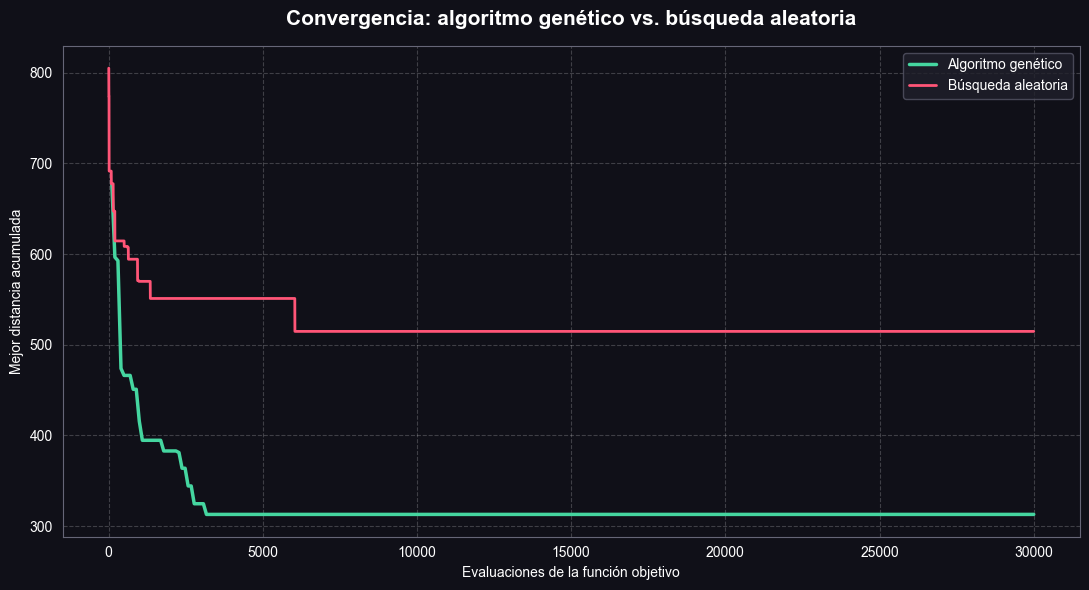

In [12]:
# ---------------------------------------------------------
# PRÁCTICA 7 - PARTE B
# GRÁFICA DE CONVERGENCIA
# ---------------------------------------------------------

import matplotlib.pyplot as plt

# Extraer evaluaciones y mejores distancias acumuladas.
eval_ag, dist_ag = zip(*resultado_ag["historial"])

eval_aleatorio, dist_aleatorio = zip(
    *resultado_aleatorio["historial"]
)

fig, ax = plt.subplots(figsize=(11, 6))

fig.patch.set_facecolor("#101018")
ax.set_facecolor("#101018")

# Algoritmo genético.
ax.plot(
    eval_ag,
    dist_ag,
    color="#45D6A0",
    linewidth=2.5,
    label="Algoritmo genético"
)

# Búsqueda aleatoria.
ax.plot(
    eval_aleatorio,
    dist_aleatorio,
    color="#FF5577",
    linewidth=2,
    label="Búsqueda aleatoria"
)

ax.set_title(
    "Convergencia: algoritmo genético vs. búsqueda aleatoria",
    fontsize=15,
    fontweight="bold",
    color="white",
    pad=15
)

ax.set_xlabel("Evaluaciones de la función objetivo", color="white")
ax.set_ylabel("Mejor distancia acumulada", color="white")

ax.tick_params(colors="white")
ax.grid(alpha=0.2, linestyle="--")

ax.legend(
    facecolor="#20202B",
    edgecolor="#555566",
    labelcolor="white"
)

for spine in ax.spines.values():
    spine.set_color("#666677")

plt.tight_layout()
plt.show()

## Dibujar la mejor ruta del algoritmo genético

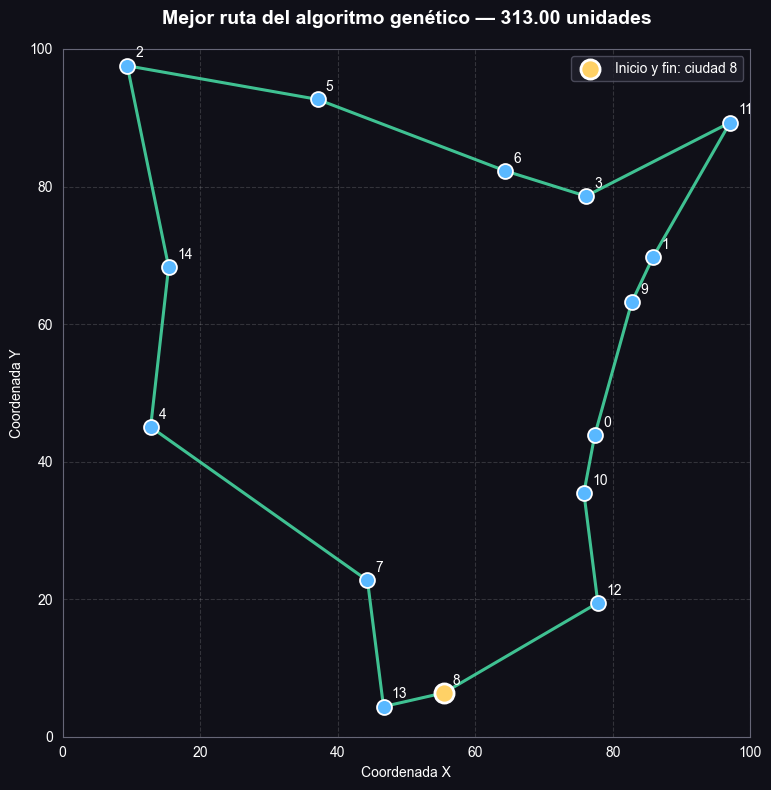

MEJOR RUTA ENCONTRADA:
8 -> 12 -> 10 -> 0 -> 9 -> 1 -> 11 -> 3 -> 6 -> 5 -> 2 -> 14 -> 4 -> 7 -> 13 -> 8

DISTANCIA TOTAL: 313.00 unidades
RUTA VÁLIDA: True
REGRESA AL INICIO: True


In [13]:
# ---------------------------------------------------------
# PRÁCTICA 7 - PARTE B
# VISUALIZACIÓN DE LA MEJOR RUTA DEL ALGORITMO GENÉTICO
# ---------------------------------------------------------

# Recuperar la mejor ruta y su distancia.
mejor_ruta = resultado_ag["mejor_ruta"]
mejor_distancia = resultado_ag["mejor_distancia"]

# Cerrar el recorrido regresando a la primera ciudad.
ruta_cerrada = mejor_ruta + [mejor_ruta[0]]

# Obtener las coordenadas en el orden de la ruta.
coordenadas_ruta = ciudades[ruta_cerrada]

fig, ax = plt.subplots(figsize=(9, 8))

fig.patch.set_facecolor("#101018")
ax.set_facecolor("#101018")

# Dibujar los tramos del recorrido.
ax.plot(
    coordenadas_ruta[:, 0],
    coordenadas_ruta[:, 1],
    color="#45D6A0",
    linewidth=2.2,
    alpha=0.9,
    zorder=1
)

# Dibujar las 15 ciudades.
ax.scatter(
    ciudades[:, 0],
    ciudades[:, 1],
    color="#59B8FF",
    s=115,
    edgecolors="white",
    linewidths=1.3,
    zorder=2
)

# Identificar cada ciudad por su número.
for i, (x, y) in enumerate(ciudades):
    ax.annotate(
        str(i),
        (x, y),
        xytext=(6, 6),
        textcoords="offset points",
        color="white",
        fontsize=10
    )

# Destacar la ciudad donde inicia y termina el recorrido.
ciudad_inicio = mejor_ruta[0]

ax.scatter(
    ciudades[ciudad_inicio, 0],
    ciudades[ciudad_inicio, 1],
    color="#FFD166",
    s=190,
    edgecolors="white",
    linewidths=2,
    zorder=3,
    label=f"Inicio y fin: ciudad {ciudad_inicio}"
)

ax.set_title(
    f"Mejor ruta del algoritmo genético — {mejor_distancia:.2f} unidades",
    fontsize=14,
    fontweight="bold",
    color="white",
    pad=18
)

ax.set_xlabel("Coordenada X", color="white")
ax.set_ylabel("Coordenada Y", color="white")

ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.set_aspect("equal")

ax.tick_params(colors="white")
ax.grid(alpha=0.15, linestyle="--")

ax.legend(
    facecolor="#20202B",
    edgecolor="#555566",
    labelcolor="white"
)

for spine in ax.spines.values():
    spine.set_color("#666677")

plt.tight_layout()
plt.show()

print("MEJOR RUTA ENCONTRADA:")
print(" -> ".join(map(str, ruta_cerrada)))

print(f"\nDISTANCIA TOTAL: {mejor_distancia:.2f} unidades")

print("RUTA VÁLIDA:", ruta_valida(mejor_ruta))
print("REGRESA AL INICIO:", ruta_cerrada[0] == ruta_cerrada[-1])

## Experimentar con distintos parámetros

In [15]:
# ---------------------------------------------------------
# PRÁCTICA 7 - PARTE B
# EXPERIMENTOS CON PARÁMETROS DEL ALGORITMO GENÉTICO
# ---------------------------------------------------------

import pandas as pd

configuraciones = [
    (50, 0.10),
    (50, 0.30),
    (100, 0.10),
    (100, 0.30)
]

resultados_experimentos = []

for numero, (poblacion, mutacion) in enumerate(
    configuraciones, start=1
):

    resultado = algoritmo_genetico(
        tamano_poblacion=poblacion,
        probabilidad_mutacion=mutacion,
        max_evaluaciones=30000,
        semilla=42
    )

    # Comprobar que cada experimento sea válido.
    assert resultado["evaluaciones"] == 30000
    assert ruta_valida(resultado["mejor_ruta"])

    resultados_experimentos.append({
        "Experimento": numero,
        "Población": poblacion,
        "Mutación (%)": int(mutacion * 100),
        "Mejor distancia": round(
            resultado["mejor_distancia"], 2
        ),
        "Evaluaciones": resultado["evaluaciones"],
        "Generaciones": resultado["generaciones"]
    })

    print(
        f"Experimento {numero}/4 completado: "
        f"población={poblacion}, "
        f"mutación={mutacion:.0%}, "
        f"distancia={resultado['mejor_distancia']:.2f}"
    )

# Crear la tabla comparativa.
tabla_experimentos = pd.DataFrame(
    resultados_experimentos
)

print("\nTABLA COMPARATIVA DE EXPERIMENTOS\n")
print(tabla_experimentos.to_string(index=False))

# Identificar todas las configuraciones que obtuvieron
# la menor distancia, incluyendo posibles empates.

distancia_minima = tabla_experimentos["Mejor distancia"].min()

configuraciones_empatadas = tabla_experimentos[
    tabla_experimentos["Mejor distancia"] == distancia_minima
]

print("\nCONFIGURACIONES EMPATADAS EN LA MEJOR DISTANCIA:")
print(
    configuraciones_empatadas[
        ["Población", "Mutación (%)", "Mejor distancia"]
    ].to_string(index=False)
)

print(f"\nMejor distancia obtenida: {distancia_minima:.2f} unidades")

Experimento 1/4 completado: población=50, mutación=10%, distancia=313.00
Experimento 2/4 completado: población=50, mutación=30%, distancia=313.00
Experimento 3/4 completado: población=100, mutación=10%, distancia=313.00
Experimento 4/4 completado: población=100, mutación=30%, distancia=313.00

TABLA COMPARATIVA DE EXPERIMENTOS

 Experimento  Población  Mutación (%)  Mejor distancia  Evaluaciones  Generaciones
           1         50            10            313.0         30000           612
           2         50            30            313.0         30000           612
           3        100            10            313.0         30000           303
           4        100            30            313.0         30000           303

CONFIGURACIONES EMPATADAS EN LA MEJOR DISTANCIA:
 Población  Mutación (%)  Mejor distancia
        50            10            313.0
        50            30            313.0
       100            10            313.0
       100            30            3